In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:

data_url = "https://hbiostat.org/data/repo/diabetes.csv"


df = pd.read_csv(data_url)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Number of rows: 403
Number of columns: 19


,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,NaN,NaN,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,NaN,NaN,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,185.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,NaN,NaN,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,NaN,NaN,44.0,41.0,300.0


In [3]:
# Display dataset information
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Display numerical summary statistics
print("\nSummary statistics:")
display(df.describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        403 non-null    int64  
 1   chol      402 non-null    float64
 2   stab.glu  403 non-null    int64  
 3   hdl       402 non-null    float64
 4   ratio     402 non-null    float64
 5   glyhb     390 non-null    float64
 6   location  403 non-null    object 
 7   age       403 non-null    int64  
 8   gender    403 non-null    object 
 9   height    398 non-null    float64
 10  weight    402 non-null    float64
 11  frame     391 non-null    object 
 12  bp.1s     398 non-null    float64
 13  bp.1d     398 non-null    float64
 14  bp.2s     141 non-null    float64
 15  bp.2d     141 non-null    float64
 16  waist     401 non-null    float64
 17  hip       401 non-null    float64
 18  time.ppn  400 non-null    float64
dtypes: float64(13), int64(3), object(3)
memory usage: 

,id,chol,stab.glu,hdl,ratio,glyhb,age,height,weight,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
count,403.000000,402.000000,403.000000,402.000000,402.000000,390.000000,403.000000,398.000000,402.000000,398.000000,398.000000,141.000000,141.000000,401.000000,401.000000,400.000000
mean,15978.310174,207.845771,106.672457,50.445274,4.521642,5.589769,46.851117,66.020101,177.592040,136.904523,83.321608,152.382979,92.524823,37.900249,43.039900,341.250000
std,11881.122124,44.445557,53.076655,17.262626,1.727886,2.242595,16.312333,3.918515,40.340666,22.741033,13.589227,21.712952,11.555198,5.729313,5.656713,309.540953
min,1000.000000,78.000000,48.000000,12.000000,1.500000,2.680000,19.000000,52.000000,99.000000,90.000000,48.000000,110.000000,60.000000,26.000000,30.000000,5.000000
25%,4792.500000,179.000000,81.000000,38.000000,3.200000,4.380000,34.000000,63.000000,151.000000,121.250000,75.000000,138.000000,84.000000,33.000000,39.000000,90.000000
50%,15766.000000,204.000000,89.000000,46.000000,4.200000,4.840000,45.000000,66.000000,172.500000,136.000000,82.000000,149.000000,92.000000,37.000000,42.000000,240.000000
75%,20336.000000,230.000000,106.000000,59.000000,5.400000,5.600000,60.000000,69.000000,200.000000,146.750000,90.000000,161.000000,100.000000,41.000000,46.000000,517.500000
max,41756.000000,443.000000,385.000000,120.000000,19.299999,16.110001,92.000000,76.000000,325.000000,250.000000,124.000000,238.000000,124.000000,56.000000,64.000000,1560.000000


In [4]:
def clean_data(data):
    """
    Clean the dataset by:
    1. Removing duplicate rows.
    2. Removing the patient ID column.
    3. Removing blood pressure columns with extensive missing data.
    4. Filling missing numerical values with the median.
    5. Filling missing categorical values with the mode.
    """

    # Work on a copy to preserve the original dataset
    cleaned = data.copy()

    # Remove exact duplicate rows
    cleaned = cleaned.drop_duplicates()

    # Remove the patient identifier
    cleaned = cleaned.drop(columns=["id"], errors="ignore")

    # Remove columns with extensive missing values
    cleaned = cleaned.drop(
        columns=["bp.2s", "bp.2d"],
        errors="ignore"
    )

    # Fill missing numerical values with the median
    numerical_columns = cleaned.select_dtypes(
        include=np.number
    ).columns

    for column in numerical_columns:
        median_value = cleaned[column].median()
        cleaned[column] = cleaned[column].fillna(median_value)

    # Fill missing categorical values with the mode
    categorical_columns = cleaned.select_dtypes(
        include=["object", "category"]
    ).columns

    for column in categorical_columns:
        if cleaned[column].isnull().any():
            mode_values = cleaned[column].mode()

            if not mode_values.empty:
                cleaned[column] = cleaned[column].fillna(
                    mode_values.iloc[0]
                )

    return cleaned


# Apply the cleaning function
cleaned_df = clean_data(df)

print("Data cleaning completed.")
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)

print("\nMissing values after cleaning:")
print(cleaned_df.isnull().sum())

display(cleaned_df.head())

Data cleaning completed.
Original dataset shape: (403, 19)
Cleaned dataset shape: (403, 16)

Missing values after cleaning:
chol        0
stab.glu    0
hdl         0
ratio       0
glyhb       0
location    0
age         0
gender      0
height      0
weight      0
frame       0
bp.1s       0
bp.1d       0
waist       0
hip         0
time.ppn    0
dtype: int64


,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,waist,hip,time.ppn
0,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,29.0,38.0,720.0
1,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,46.0,48.0,360.0
2,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,49.0,57.0,180.0
3,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,33.0,38.0,480.0
4,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,44.0,41.0,300.0


In [5]:
# Select numerical columns
numerical_data = cleaned_df.select_dtypes(
    include=np.number
)

# Convert the numerical data into a NumPy array
data_array = numerical_data.to_numpy(dtype=float)

print("NumPy processing completed.")
print("Array shape:", data_array.shape)

# Calculate statistics for each numerical column
column_means = np.mean(data_array, axis=0)
column_medians = np.median(data_array, axis=0)
column_minimums = np.min(data_array, axis=0)
column_maximums = np.max(data_array, axis=0)
column_stds = np.std(data_array, axis=0)

# Display the results in a table
statistics = pd.DataFrame({
    "Column": numerical_data.columns,
    "Mean": column_means,
    "Median": column_medians,
    "Minimum": column_minimums,
    "Maximum": column_maximums,
    "Standard Deviation": column_stds
})

display(statistics.round(2))

NumPy processing completed.
Array shape: (403, 13)


,Column,Mean,Median,Minimum,Maximum,Standard Deviation
0,chol,207.84,204.00,78.00,443.00,44.34
1,stab.glu,106.67,89.00,48.00,385.00,53.01
2,hdl,50.43,46.00,12.00,120.00,17.22
3,ratio,4.52,4.20,1.50,19.30,1.72
4,glyhb,5.57,4.84,2.68,16.11,2.21
5,age,46.85,45.00,19.00,92.00,16.29
6,height,66.02,66.00,52.00,76.00,3.89
7,weight,177.58,172.50,99.00,325.00,40.24
8,bp.1s,136.89,136.00,90.00,250.00,22.57
9,bp.1d,83.31,82.00,48.00,124.00,13.49


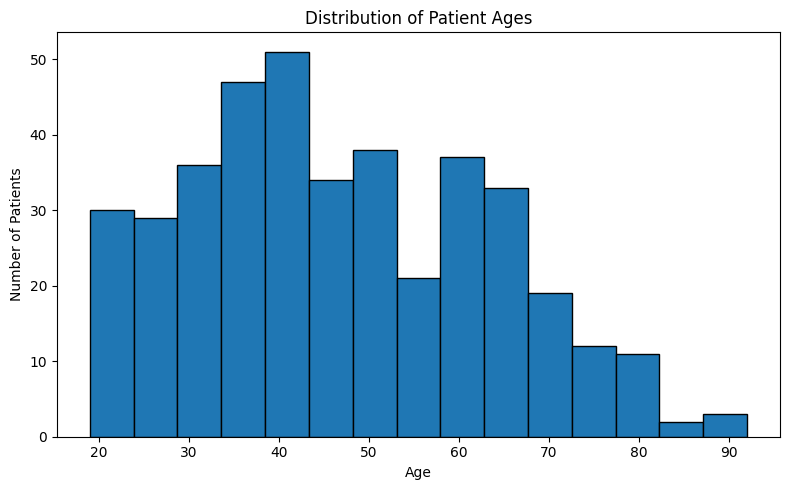

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(cleaned_df["age"], bins=15, edgecolor="black")

plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [7]:
output_file = "cleaned_diabetes.csv"

cleaned_df.to_csv(output_file, index=False)

print(f"Cleaned dataset saved as: {output_file}")

Cleaned dataset saved as: cleaned_diabetes.csv


In [8]:
from google.colab import files

files.download("cleaned_diabetes.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
%%writefile requirements.txt
numpy
pandas
matplotlib
jupyter

Writing requirements.txt


In [10]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>